# code_091 · Stacking blending and hybrid ensembles

**Book:** section 18.5. A self-contained trees-and-ensembles laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_18_GUIDE.md), [run evidence](../CHAPTER_18_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_091).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=1891;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 1891


<a id="stack"></a>
## Train a meta-model on predictions made without each target

Generate training180/development80/final200 cases with four standard normal features and response .6*x0+.8*x1²+.4*sin3x2+NormalSD.2. Base learners are fixed HistGradientBoostingRegressor(60rounds,leaf7,minleaf10), standardized Ridge(alpha1), and standardized trained MLPRegressor(12tanh hidden units,L-BFGS,max_iter2000,alpha.1). Five fixed KFold masks produce180×3OOFpredictions. Fit the ENTIRE standardized base pipeline inside each fold; no query target enters its scaler or base fit. Full-training base models then provide development/final predictions. Ridge meta alpha[.1,1,10] is selected by development MSE. Compare frozen bases, uniform averaging and the selected stack on final. The head may use negative coefficients, so its output is not a convex average.

A separate honest blending candidate uses only120training records for base fits and disjoint60for its fixed Ridge1head. It retains those120-case base models at deployment rather than silently refitting them on the blending targets. These different data budgets are disclosed. Development is not silently used to train the stack head. An in-sample base-prediction matrix is retained solely as an invalid training diagnostic, not a meta-training alternative selected on final outcomes.


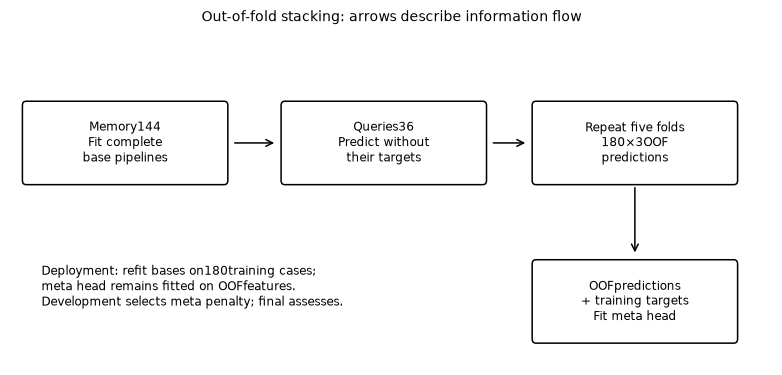

In [2]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
from scipy.special import expit
from scipy.optimize import minimize
def generate(n):
 a=rng.normal(size=(n,4));return a,.6*a[:,0]+.8*a[:,1]**2+.4*np.sin(3*a[:,2])+rng.normal(0,.2,n)
X,y=generate(180);Xd,yd=generate(80);Xt,yt=generate(200)
def make(name):
 if name=='Boosted tree':return HistGradientBoostingRegressor(max_iter=60,max_leaf_nodes=7,min_samples_leaf=10,learning_rate=.1,early_stopping=False,random_state=SEED)
 if name=='Ridge':return make_pipeline(StandardScaler(),Ridge(alpha=1))
 return make_pipeline(StandardScaler(),MLPRegressor(hidden_layer_sizes=(12,),activation='tanh',solver='lbfgs',alpha=.1,max_iter=2000,tol=1e-5,random_state=SEED))
names=['Boosted tree','Ridge','Neural'];oof=np.zeros((len(y),3));seen=np.zeros(len(y),int);fold_sizes=[]
for train,valid in KFold(5,shuffle=True,random_state=SEED).split(X):
 assert not set(train)&set(valid);seen[valid]+=1;fold_sizes.append({'base_training_rows':len(train),'OOF_query_rows':len(valid),'overlap':0})
 for j,name in enumerate(names):fit=make(name).fit(X[train],y[train]);oof[valid,j]=fit.predict(X[valid])
np.testing.assert_array_equal(seen,np.ones(len(y),int));full={name:make(name).fit(X,y) for name in names};D=np.column_stack([full[name].predict(Xd) for name in names]);T=np.column_stack([full[name].predict(Xt) for name in names]);options=[]
for alpha in [.1,1,10]:
 head=Ridge(alpha=alpha).fit(oof,y);options.append((float(mean_squared_error(yd,head.predict(D))),alpha,head))
dev,alpha,head=min(options,key=lambda v:v[0]);rows=[{'model':name,'final_mse':float(mean_squared_error(yt,T[:,j]))} for j,name in enumerate(names)];rows += [{'model':'Uniform mean','final_mse':float(mean_squared_error(yt,T.mean(axis=1)))},{'model':'OOF stack','final_mse':float(mean_squared_error(yt,head.predict(T)))}]
ids=rng.permutation(len(y));base_ids,blend_ids=ids[:120],ids[120:];assert not set(base_ids)&set(blend_ids);blend_models=[make(name).fit(X[base_ids],y[base_ids]) for name in names];blend_train=np.column_stack([m.predict(X[blend_ids]) for m in blend_models]);blend_test=np.column_stack([m.predict(Xt) for m in blend_models]);blend=Ridge(alpha=1).fit(blend_train,y[blend_ids]);rows.append({'model':'Disjoint blend','final_mse':float(mean_squared_error(yt,blend.predict(blend_test)))})
inside=np.column_stack([full[name].predict(X) for name in names]);RESULTS['ensemble']={'roles':{'training':180,'development':80,'final':200},'OOF_fold_ledger':fold_sizes,'meta_alpha':alpha,'development_mse':dev,'meta_coefficients':head.coef_.tolist(),'meta_intercept':float(head.intercept_),'final_scores':rows,'OOF_base_mse':[float(mean_squared_error(y,oof[:,j])) for j in range(3)],'invalid_in_sample_base_mse':[float(mean_squared_error(y,inside[:,j])) for j in range(3)],'blend_base_training_rows':120,'blend_head_training_rows':60,'blend_bases_refit_on_head_targets':False};RESULTS['neural_fit']={'full_training_iterations':int(full['Neural'][-1].n_iter_),'max_iter':2000,'hidden_units':12,'activation':'tanh','solver':'lbfgs'}
# Original diagram of actual OOF roles, distinct from sequential residual correction.
fig,ax=plt.subplots(figsize=(7,3.3));ax.set(xlim=(0,10),ylim=(0,4));ax.axis('off');boxes=[(.2,2.2,2.6,.9,'Memory144\nFit complete\nbase pipelines'),(3.6,2.2,2.6,.9,'Queries36\nPredict without\ntheir targets'),(6.9,2.2,2.6,.9,'Repeat five folds\n180×3OOF\npredictions'),(6.9,.3,2.6,.9,'OOFpredictions\n+ training targets\nFit meta head')]
from matplotlib.patches import FancyBboxPatch
for x0,y0,w,h,label in boxes:ax.add_patch(FancyBboxPatch((x0,y0),w,h,boxstyle='round,pad=.05',facecolor='white',edgecolor='black'));ax.text(x0+w/2,y0+h/2,label,ha='center',va='center',fontsize=8)
for a,b in [((2.9,2.65),(3.5,2.65)),((6.3,2.65),(6.8,2.65)),((8.2,2.15),(8.2,1.3))]:ax.annotate('',xy=b,xytext=a,arrowprops=dict(arrowstyle='->',color='black'))
ax.text(.4,.7,'Deployment: refit bases on180training cases;\nmeta head remains fitted on OOFfeatures.\nDevelopment selects meta penalty; final assesses.',fontsize=8);ax.set_title('Out-of-fold stacking: arrows describe information flow');plt.show()


<a id="soft"></a>
## A soft-routing candidate needs its own evidence

For an original one-split differentiable mechanism, fix routing direction and threshold and fit two leaf values to training data through gate=sigmoid(4*x0). Solve a small least-squares problem on columns[1-gate,gate], then verify the prediction identity. This soft stump has continuous routing; it is not a trained deep differentiable forest or a competitive benchmark claim. The scalar gate derivative 4*g*(1-g) is checked by finite differences. A steep gate approximates the hard threshold away from zero, but optimization, feature selection, calibration and external validation remain separate questions. Display its limited final loss beside the honest ensemble comparisons without selecting the gate on final data.


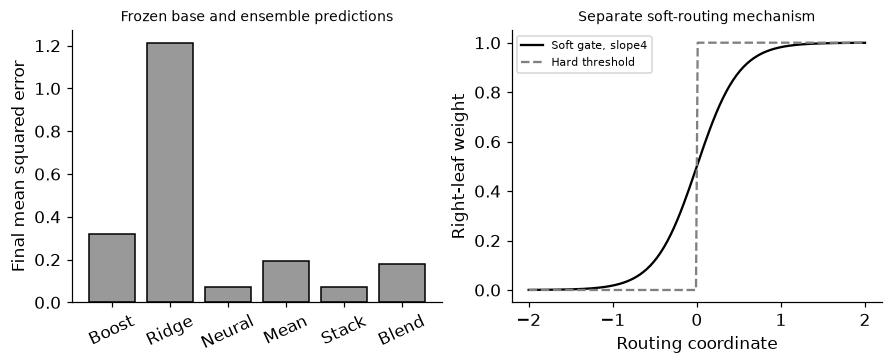

In [3]:
gate=expit(4*X[:,0]);design=np.column_stack([1-gate,gate]);leaf=np.linalg.lstsq(design,y,rcond=None)[0];tg=expit(4*Xt[:,0]);soft=(1-tg)*leaf[0]+tg*leaf[1];np.testing.assert_allclose(soft,np.column_stack([1-tg,tg])@leaf);x0=.3;h=1e-6;numeric=(expit(4*(x0+h))-expit(4*(x0-h)))/(2*h);np.testing.assert_allclose(numeric,4*expit(4*x0)*(1-expit(4*x0)),atol=1e-9);assert expit(1000*.1)>.999 and expit(-1000*.1)<.001
RESULTS['soft_stump']={'fixed_gate_slope':4,'fixed_threshold':0,'fitted_leaf_values':leaf.tolist(),'final_mse':float(mean_squared_error(yt,soft)),'deep_differentiable_forest_executed':False};fig,axes=plt.subplots(1,2,figsize=(8,3.2));axes[0].bar(range(len(rows)),[r['final_mse'] for r in rows],color='.6',edgecolor='black');axes[0].set(xticks=range(len(rows)),xticklabels=['Boost','Ridge','Neural','Mean','Stack','Blend'],ylabel='Final mean squared error',title='Frozen base and ensemble predictions');axes[0].tick_params(axis='x',labelrotation=25);g=np.linspace(-2,2,200);axes[1].plot(g,expit(4*g),color='black',label='Soft gate, slope4');axes[1].plot(g,(g>0).astype(float),'--',color='.5',label='Hard threshold');axes[1].set(xlabel='Routing coordinate',ylabel='Right-leaf weight',title='Separate soft-routing mechanism');axes[1].legend(fontsize=7);plt.show()


In [4]:
summary={'example_id':'code_091','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['entire-pipeline out-of-fold base predictions', 'boosted tree ridge and trained neural base learners', 'honest holdout blending versus full-memory deployment', 'soft-routing candidate as a scoped mechanism'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["entire-pipeline out-of-fold base predictions", "boosted tree ridge and trained neural base learners", "honest holdout blending versus full-memory deployment", "soft-routing candidate as a scoped mechanism"], "elapsed_seconds": 0.676, "example_id": "code_091", "hardware": "Darwin arm64 CPU", "results": {"ensemble": {"OOF_base_mse": [0.5752131473562362, 1.8411197288159742, 0.19478658089920317], "OOF_fold_ledger": [{"OOF_query_rows": 36, "base_training_rows": 144, "overlap": 0}, {"OOF_query_rows": 36, "base_training_rows": 144, "overlap": 0}, {"OOF_query_rows": 36, "base_training_rows": 144, "overlap": 0}, {"OOF_query_rows": 36, "base_training_rows": 144, "overlap": 0}, {"OOF_query_rows": 36, "base_training_rows": 144, "overlap": 0}], "blend_base_training_rows": 120, "blend_bases_refit_on_head_targets": false, "blend_head_training_rows": 60, "development_mse": 0.10573204950406963, "final_scores": [{"final_mse": 0.31991501363474895, "model